# CSE 4310
# Programming Assignment 4 (PA4)
Alex Nguyen | 1002097417

# Eigenfaces

## Task A (30 points)
1. Load all the 25 images in the "/Eigenfaces/Train"
2. Display all the original faces in a 5X5 grid.
3. Find the mean face image. Perform PCA on the training faces.
4. Display the mean face.
5. Diplay all the eigenfaces in a 5X5 grid.

## Task B (30 points)

1. Select k = 2 eigenfaces (eigenvectors that correspond to the largest eigenvalues).
2. Reconstruct the training faces and display the reconstructed faces in a 5X5 grid.
3. Repeat the process for k = 5 and k = 15. For each k, reconstruct the training faces and display the reconstructed image in a 5X5 grid.


## Task C (40 points)
1. Load all the test images from "/Eigenfaces/Test"
2. Project each test image on the k = 2 eigenvectors and detect if it's a face. If it's a face, find it's closest training image. Use euclidean distance to calculate distance.
3. Display all the results in an M X 2 table, where M is total no of test images. Each row of the table displays two images. The image on the left is the test image. The image on the right is it's closest image in the eigenfaces space (Display the closest Training Image) . If an image is classified as a non-face, then the second column in the table should be blank (Just display a black image).
4. Repeat the process and display the results for k = 5, k = 15.

In [1]:
# TASK A
import os


import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
# Load Images

# We will make a function for this since I obviously will later have to do this for both train and test.
def load_images(folder, size=None):
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(".jpg"))

    images  = []
    for f in files:
        img = cv2.imread(os.path.join(folder,f), cv2.IMREAD_GRAYSCALE)
        if size is None:
            size = (img.shape[1], img.shape[0])
        if (img.shape[1], img.shape[0]) != size:
            img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
        images.append(img.astype(np.float64) / 255.0)
    return np.stack(images), files

In [3]:
# Find Mean face
# I intended to make this a function when I first planned skeleton code, but now I see getting mean face is easy.
def find_mean_face(images):
    return images.mean(axis=0)

In [4]:
# PCA time
def perform_PCA(images):
    # Must reshape so we get less eigenfaces (25) 
    n = images.shape[0]
    X = images.reshape(n, -1)
    mean_face = find_mean_face(X) 

    # Compute covar matrix :D
    A = X - mean_face
    L = A @ A.T
    eigvals, V = np.linalg.eigh(L)
    
    # Find most dominant eigevector now
    order = np.argsort(eigvals)[::-1]
    eigals = eigvals[order]
    V = V[:, order]

    # I realized I can also compute eigenfaces in this step while I still have A
    U = A.T @ V
    U = U / np.linalg.norm(U, axis=0)
    eigenfaces = U.T

    return mean_face, eigenfaces

# After I makde this function get eigenfaces, it means the function is slightly misnamed, but that's OK for me

In [5]:
# Helper to display images cleanly (lesson learned from doing manually everytime)
def show_grid(imgs, h, w, title, auto_contrast=False):
    fig, axes = plt.subplots(5, 5, figsize=(5, 5))
    for i, ax in enumerate(axes.ravel()):
        if auto_contrast:
            ax.imshow(imgs[i].reshape(h, w), cmap="gray")
        else:
            ax.imshow(imgs[i].reshape(h, w), cmap="gray", vmin=0, vmax=1)
        ax.set_title(str(i + 1), fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

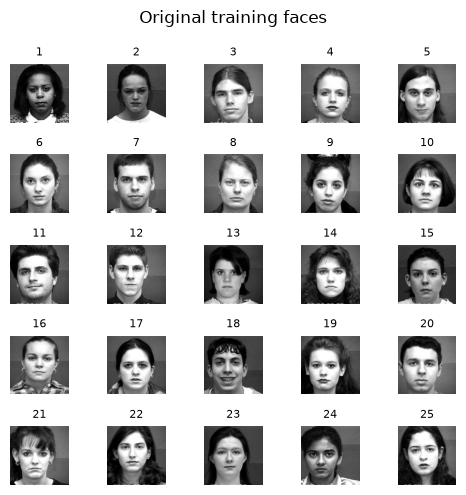

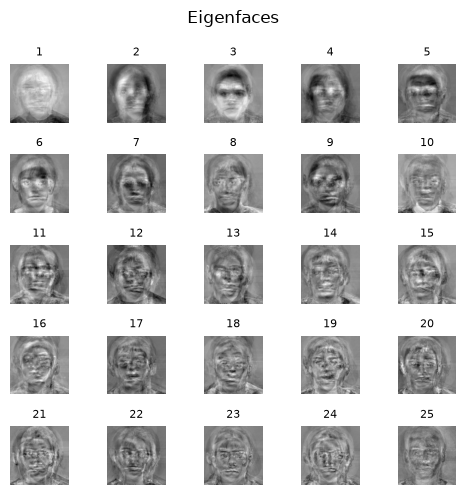

In [6]:
# Task A
train_images, _ = load_images("./Eigenfaces/Train/")

n, h, w = train_images.shape
mean_face, eigenfaces = perform_PCA(train_images)

show_grid(train_images, h, w, "Original training faces")             # A.2
show_grid(eigenfaces, h, w, "Eigenfaces", auto_contrast=True)         # A.5

In [7]:
def k_creation(k, mean_face, eigenfaces, to_be_projected_face):
    # Get Projeection
    W = (to_be_projected_face - mean_face) @ eigenfaces[:k].T


    reprojected = mean_face + W @ eigenfaces[:k]

    return reprojected

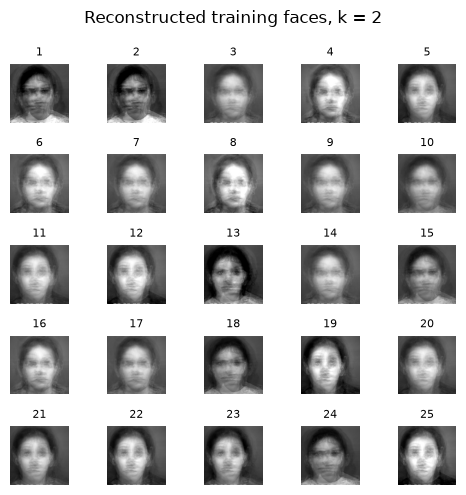

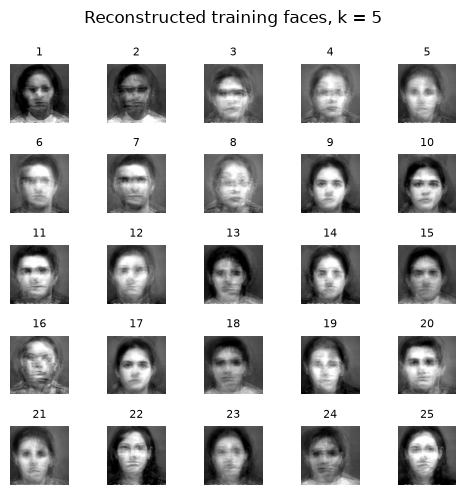

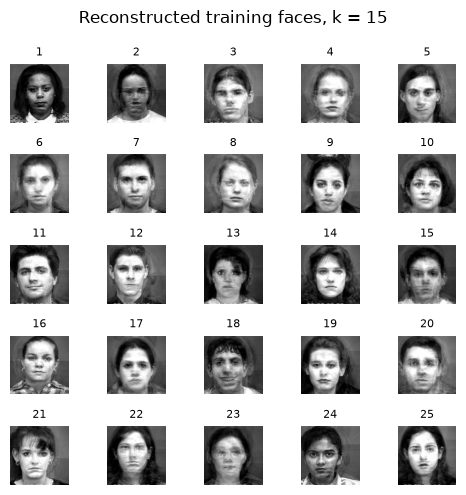

In [8]:
n, h, w = train_images.shape
X = train_images.reshape(n, -1)                 # (25, h*w)

reprojected_k2 = k_creation(2, find_mean_face(X), eigenfaces, X)
reprojected_k5 = k_creation(5, find_mean_face(X), eigenfaces, X)
reprojected_k15 = k_creation(15, find_mean_face(X), eigenfaces, X)
show_grid(reprojected_k2, h, w, "Reconstructed training faces, k = 2")
show_grid(reprojected_k5, h, w, "Reconstructed training faces, k = 5")
show_grid(reprojected_k15, h, w, "Reconstructed training faces, k = 15")

In [9]:
# TASK C
# Load test images at the same size as the training images
test_images, test_files = load_images("./Eigenfaces/Test/", size=(w, h))
X_test = test_images.reshape(len(test_images), -1)

In [10]:
# Face threshold: leave one training face out, redo PCA on the other 24, and see how far
# the left-out face is from its reconstruction. The worst of these is how far a face the
# model has never seen can be from face space.
def face_threshold(k, X, margin=1.1):
    errors = []
    for i in range(len(X)):
        others = np.delete(X, i, axis=0)
        mean_i, eigenfaces_i = perform_PCA(others)
        rebuilt = k_creation(k, mean_i, eigenfaces_i, X[i:i + 1])
        errors.append(np.linalg.norm(X[i] - rebuilt[0]))
    return margin * max(errors)

In [11]:
def run_task_c(k):
    threshold = face_threshold(k, X)

    # Face or not: how far each test image is from its reconstruction
    rebuilt = k_creation(k, mean_face, eigenfaces, X_test)
    errors = np.linalg.norm(X_test - rebuilt, axis=1)

    # Weights in face space (same projection as inside k_creation)
    W_train = (X - mean_face) @ eigenfaces[:k].T
    W_test = (X_test - mean_face) @ eigenfaces[:k].T

    print(f"k = {k}, face threshold = {threshold:.2f}")
    M = len(X_test)
    fig, axes = plt.subplots(M, 2, figsize=(4, 2 * M), squeeze=False)
    for i in range(M):
        axes[i, 0].imshow(test_images[i], cmap="gray", vmin=0, vmax=1)

        if errors[i] <= threshold:
            # Closest training face by Euclidean distance between weights
            distances = np.linalg.norm(W_train - W_test[i], axis=1)
            j = np.argmin(distances)
            axes[i, 1].imshow(train_images[j], cmap="gray", vmin=0, vmax=1)
            axes[i, 0].set_title(f"{test_files[i]}: face", fontsize=8)
            axes[i, 1].set_title(f"closest: training face {j + 1}", fontsize=8)
            print(f"  {test_files[i]:<15} error {errors[i]:6.2f}  face, closest training face {j + 1}")
        else:
            # Non-face: black image on the right
            axes[i, 1].imshow(np.zeros((h, w)), cmap="gray", vmin=0, vmax=1)
            axes[i, 0].set_title(f"{test_files[i]}: non-face", fontsize=8)
            print(f"  {test_files[i]:<15} error {errors[i]:6.2f}  non-face")

        axes[i, 0].axis("off")
        axes[i, 1].axis("off")

    fig.suptitle(f"Task C, k = {k}")
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.5 / (2 * M)))
    plt.show()

k = 2, face threshold = 116.00
  S034_005_02293928.jpg error 125.90  non-face
  S035_005_02500507.jpg error 119.27  non-face
  S045_001_00155520.jpg error 112.62  face, closest training face 15
  S046_004_00021029.jpg error 107.39  face, closest training face 6
  S050_003_00015829.jpg error 100.46  face, closest training face 15
  S053_001_00022401.jpg error  84.67  face, closest training face 3
  S054_001_00021023.jpg error  76.67  face, closest training face 3
  S055_005_01065417.jpg error  61.43  face, closest training face 4
  S056_001_01175021.jpg error  68.25  face, closest training face 5
  S057_006_01271600.jpg error  62.36  face, closest training face 6
  S059_002_00121512.jpg error  61.96  face, closest training face 8
  S060_001_00211719.jpg error  86.47  face, closest training face 14
  S063_001_00223923.jpg error  75.73  face, closest training face 20
  S066_002_00232526.jpg error  81.35  face, closest training face 3
  S072_004_00012819.jpg error  70.31  face, closest tra

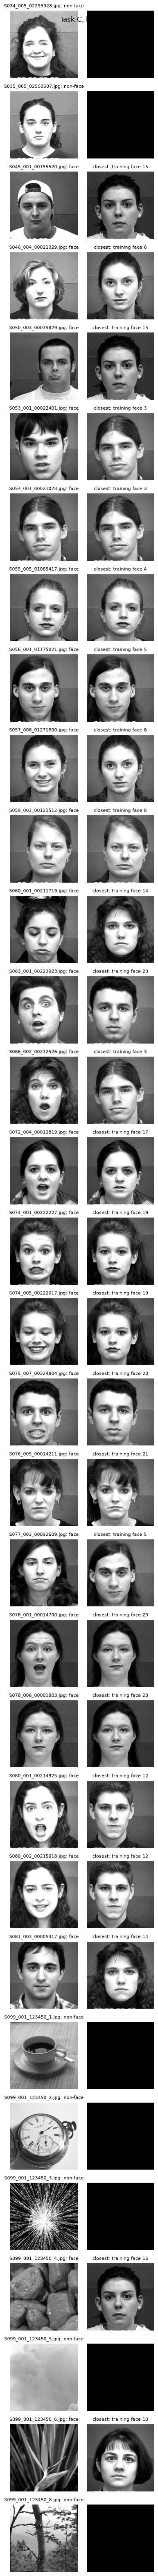

k = 5, face threshold = 93.91
  S034_005_02293928.jpg error 114.28  non-face
  S035_005_02500507.jpg error 106.71  non-face
  S045_001_00155520.jpg error 100.55  non-face
  S046_004_00021029.jpg error 102.47  non-face
  S050_003_00015829.jpg error  90.83  face, closest training face 2
  S053_001_00022401.jpg error  79.19  face, closest training face 3
  S054_001_00021023.jpg error  56.41  face, closest training face 3
  S055_005_01065417.jpg error  57.38  face, closest training face 4
  S056_001_01175021.jpg error  61.33  face, closest training face 5
  S057_006_01271600.jpg error  55.52  face, closest training face 6
  S059_002_00121512.jpg error  55.45  face, closest training face 8
  S060_001_00211719.jpg error  68.94  face, closest training face 9
  S063_001_00223923.jpg error  69.30  face, closest training face 12
  S066_002_00232526.jpg error  68.82  face, closest training face 14
  S072_004_00012819.jpg error  61.42  face, closest training face 17
  S074_001_00222227.jpg error  

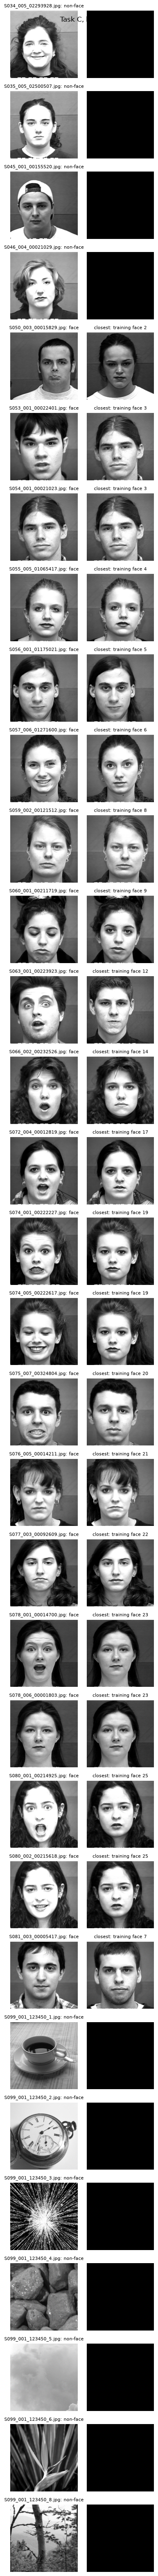

k = 15, face threshold = 91.59
  S034_005_02293928.jpg error 100.60  non-face
  S035_005_02500507.jpg error  92.23  non-face
  S045_001_00155520.jpg error  94.62  non-face
  S046_004_00021029.jpg error  93.41  non-face
  S050_003_00015829.jpg error  85.58  face, closest training face 2
  S053_001_00022401.jpg error  70.46  face, closest training face 3
  S054_001_00021023.jpg error  31.02  face, closest training face 3
  S055_005_01065417.jpg error  44.96  face, closest training face 4
  S056_001_01175021.jpg error  29.53  face, closest training face 5
  S057_006_01271600.jpg error  46.80  face, closest training face 6
  S059_002_00121512.jpg error  41.40  face, closest training face 8
  S060_001_00211719.jpg error  59.04  face, closest training face 9
  S063_001_00223923.jpg error  58.04  face, closest training face 11
  S066_002_00232526.jpg error  49.49  face, closest training face 14
  S072_004_00012819.jpg error  55.26  face, closest training face 17
  S074_001_00222227.jpg error 

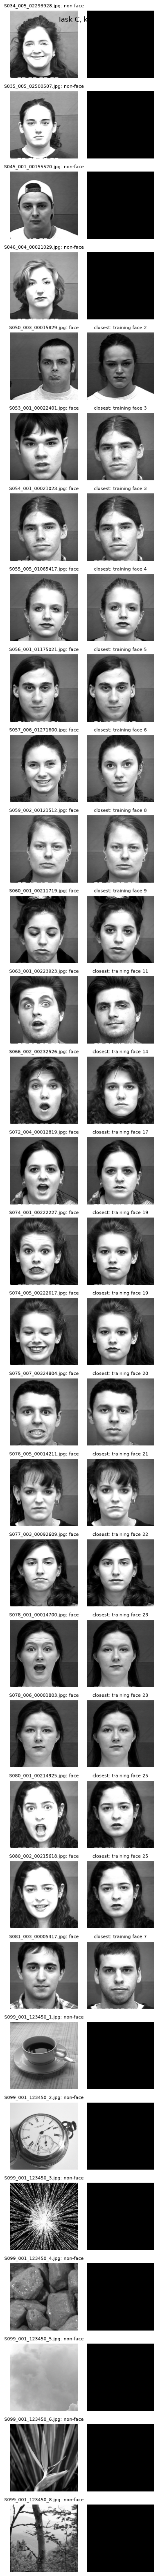

In [12]:
run_task_c(2)
run_task_c(5)
run_task_c(15)

## Submission Guidelines:



    Submit through Canvas your source code in a single .ipynb file. The name of the .ipynb file should be YourStudentID.ipynb. (For example: 1001234567.ipynb)
    Import all the images from the ./Images directory. Your TA will use the same directory name to grade your submission.
    You don't need to attach the image file with your submission.